        # Lesson 8.8 · Sequence Models: RNN, LSTM and GRU
        ### A recurrent cell by hand, the vanishing-gradient problem, LSTM and GRU gates, and PyTorch's recurrent layers

        | | |
        |---|---|
        | ⏱️ **Time** | about 110 minutes |
        | 📚 **Before you start** | Lessons 8.2 – 8.4 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Explain how an **RNN** carries a hidden state through time, and implement its forward pass by hand
- Demonstrate the **vanishing-gradient problem** and why **LSTM** and **GRU** gates fix it
- Implement an **LSTM cell** manually and match PyTorch's `nn.LSTMCell`
- Use `nn.RNN / nn.LSTM / nn.GRU` correctly: shapes, `batch_first`, last hidden state, gradient clipping

> 🌾 **The story so far.** Price at week 40 depends on what happened at week 5: a drought, a policy change. Can a network *remember* that far back? Recurrent networks are the story of how we taught machines to carry memory.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

import torch, torch.nn as nn
torch.set_num_threads(1)
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · Why sequences need memory

A feed-forward network sees a fixed-size input all at once and has no notion of "before". For sequences (prices, text, sensor streams, speech) we want:

1. **variable length** inputs, 2. **order awareness**, 3. **shared parameters across time** (the same rule applied at every step).

**Recurrent idea:** keep a **hidden state** $\mathbf h_t$ (a running summary of everything seen so far) and update it with each new input:

$$\mathbf h_t=\tanh\!\left(W_x\mathbf x_t+W_h\mathbf h_{t-1}+\mathbf b\right)$$

The *same* $W_x, W_h,\mathbf b$ are used at **every** time step (that's the parameter sharing). Unrolled in time it looks like a very deep network (one layer per time step) with tied weights.

```
x1 ─►[RNN]─h1─►[RNN]─h2─►[RNN]─h3─► … ─► hT ─► Linear ─► prediction      (many-to-one)
      ▲            ▲           ▲
     h0           same weights every step
```

| Pattern | Example |
|---|---|
| **many-to-one** | 26 weeks of prices → "price up next month?" (sequence classification/regression) |
| **many-to-many (aligned)** | label every day of a sensor stream |
| **seq2seq** | translate a sentence; forecast 8 steps from 52 |

---
### 🧩 Exercise 1: An RNN forward pass by hand  ⭐⭐

Implement `rnn_forward(X, Wx, Wh, b)` in NumPy: `X` has shape `(T, d)` (one sequence), `Wx` `(h, d)`, `Wh` `(h, h)`, `b` `(h,)`; start from `h0 = 0`.
Return an array `H` of shape `(T, h)` with the hidden state after every step. It must reproduce `torch.nn.RNN` (PyTorch uses **two** biases `b_ih + b_hh`; we merge them into one `b`).

<details><summary>💡 Hint 1: gentle nudge</summary>

`h = np.zeros(Wx.shape[0])`; loop over the rows of `X`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`h = np.tanh(Wx @ x_t + Wh @ h + b)`; append a copy of `h`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`return np.array(states)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [2]:
def rnn_forward(X, Wx, Wh, b):
    h, states = np.zeros(Wx.shape[0]), []
    for x_t in X:
        h = np.tanh(Wx @ x_t + Wh @ h + b)
        states.append(h)
    return np.array(states)

torch.manual_seed(0)
torch_rnn = nn.RNN(input_size=3, hidden_size=5, batch_first=True)
Xseq = torch.randn(1, 7, 3)
Wx_, Wh_ = torch_rnn.weight_ih_l0.detach().numpy(), torch_rnn.weight_hh_l0.detach().numpy()
b_ = (torch_rnn.bias_ih_l0 + torch_rnn.bias_hh_l0).detach().numpy()
H_mine = rnn_forward(Xseq[0].numpy(), Wx_, Wh_, b_)
print(H_mine.shape)

(7, 5)


In [3]:
with torch.no_grad(): ref = torch_rnn(Xseq)[0][0].numpy()
ag.check("shape (7, 5)", H_mine is not None and H_mine.shape == (7, 5))
ag.check("identical to torch.nn.RNN", H_mine is not None and np.allclose(H_mine, ref, atol=1e-5))

✅  shape (7, 5)
✅  identical to torch.nn.RNN


True

---
## 2 · The vanishing-gradient problem

To learn from step 1 when the loss appears at step $T$, the gradient must travel back through $T-1$ applications of $W_h$ and $\tanh'$:

$$\frac{\partial \mathbf h_T}{\partial \mathbf h_1}=\prod_{t=2}^{T}\operatorname{diag}\!\bigl(\tanh'(\cdot)\bigr)\,W_h$$

A product of many matrices with norm < 1 **shrinks exponentially** (vanishing gradient); with norm > 1 it **explodes**. After ~20 steps the early inputs have almost *no influence on the learning signal*:
the network cannot learn long-range dependencies. Let's measure it: the gradient of the last hidden state with respect to *each* input step.

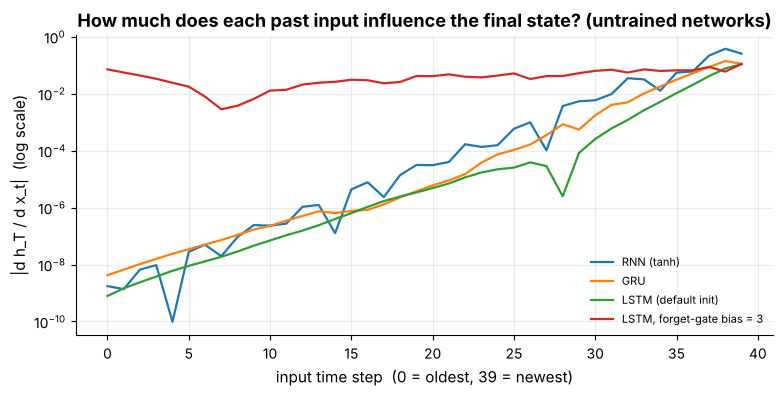

In [4]:
def grad_by_step(kind, T=40, hidden=32, seed=0, fbias=None):
    torch.manual_seed(seed)
    layer = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[kind](1, hidden, batch_first=True)
    if kind == "LSTM" and fbias is not None:                      # set the FORGET-gate bias (2nd quarter of the stacked gate biases)
        with torch.no_grad(): layer.bias_hh_l0[hidden:2 * hidden].fill_(fbias)
    x = torch.randn(1, T, 1, requires_grad=True)
    out, _ = layer(x)
    out[:, -1].sum().backward()
    return x.grad.abs().squeeze().numpy()

plt.figure(figsize=(9, 3.9))
for name, kw in [("RNN (tanh)", dict(kind="RNN")), ("GRU", dict(kind="GRU")), ("LSTM (default init)", dict(kind="LSTM")), ("LSTM, forget-gate bias = 3", dict(kind="LSTM", fbias=3.0))]:
    plt.semilogy(grad_by_step(**kw), label=name)
plt.xlabel("input time step  (0 = oldest, 39 = newest)"); plt.ylabel("|d h_T / d x_t|  (log scale)"); plt.legend(fontsize=8)
plt.title("How much does each past input influence the final state? (untrained networks)"); plt.show()

An honest and important reading of that plot:

- **At default initialisation, every recurrent layer loses the distant past**: including the LSTM. Gates give an LSTM the *capacity* to keep gradients alive, but a freshly initialised gate isn't open yet.
- Setting the **forget-gate bias to a positive number** (here 3 → forget gate $\approx\sigma(3)=0.95$ at the start) makes the cell state behave like a conveyor belt *from step one*, and the early inputs keep a gradient comparable to the recent ones. This trick (Jozefowicz et al., 2015) is standard in good LSTM code.

---
### 🧩 Exercise 2: Measure the decay: and the cure  ⭐⭐

Using `grad_by_step(..., T=30)` (seed 0), compute the ratio *(gradient at the oldest step) / (gradient at the newest step)* for:
`ratio_rnn` (plain RNN), `ratio_lstm` (LSTM, default init), `ratio_lstm_fb3` (LSTM with `fbias=3.0`).
Set `fb_matters = ratio_lstm_fb3 > 1000 * ratio_lstm`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`g = grad_by_step('RNN', T=30)`; the ratio is `g[0] / g[-1]` (oldest ÷ newest).

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

For the third, pass the keyword `fbias=3.0`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Wrap each ratio in `float(...)`. Expect the first two to be tiny (≪ 1e-3) and the third close to 1.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [5]:
r = lambda **kw: float((lambda g: g[0] / g[-1])(grad_by_step(T=30, **kw)))
ratio_rnn, ratio_lstm, ratio_lstm_fb3 = r(kind="RNN"), r(kind="LSTM"), r(kind="LSTM", fbias=3.0)
fb_matters = bool(ratio_lstm_fb3 > 1000 * ratio_lstm)
print(f"RNN {ratio_rnn:.1e} | LSTM default {ratio_lstm:.1e} | LSTM forget-bias 3: {ratio_lstm_fb3:.2f}")

RNN 8.4e-07 | LSTM default 4.1e-07 | LSTM forget-bias 3: 1.77


In [6]:
ag.check("plain RNN: the gradient from the oldest step has vanished (< 1e-3 of the newest)", ratio_rnn is not None and ratio_rnn < 1e-3)
ag.check("default-initialised LSTM also vanishes", ratio_lstm is not None and ratio_lstm < 1e-3)
ag.check("forget-bias 3 keeps the early gradient alive (> 0.01)", ratio_lstm_fb3 is not None and ratio_lstm_fb3 > 0.01)
ag.check("fb_matters is True", fb_matters is True)

✅  plain RNN: the gradient from the oldest step has vanished (< 1e-3 of the newest)
✅  default-initialised LSTM also vanishes
✅  forget-bias 3 keeps the early gradient alive (> 0.01)
✅  fb_matters is True


True

---
## 3 · LSTM: memory with gates

Hochreiter & Schmidhuber (1997) added a second state (the **cell state** $\mathbf c_t$) a "conveyor belt" running through time with only *gentle, gated* edits.
Because $\mathbf c_t$ is updated **additively**, gradients can flow along it almost unchanged.

Three **gates** (each a sigmoid in (0,1), computed from $\mathbf x_t$ and $\mathbf h_{t-1}$) control the belt:

$$\begin{aligned}
\mathbf i_t&=\sigma(W_{i}[\mathbf x_t,\mathbf h_{t-1}]+\mathbf b_i) &&\text{input gate: how much new info to write}\\
\mathbf f_t&=\sigma(W_{f}[\mathbf x_t,\mathbf h_{t-1}]+\mathbf b_f) &&\text{forget gate: how much old memory to keep}\\
\mathbf g_t&=\tanh(W_{g}[\mathbf x_t,\mathbf h_{t-1}]+\mathbf b_g) &&\text{candidate content}\\
\mathbf o_t&=\sigma(W_{o}[\mathbf x_t,\mathbf h_{t-1}]+\mathbf b_o) &&\text{output gate: how much memory to reveal}\\[2pt]
\mathbf c_t&=\mathbf f_t\odot\mathbf c_{t-1}+\mathbf i_t\odot\mathbf g_t &&\text{update the belt}\\
\mathbf h_t&=\mathbf o_t\odot\tanh(\mathbf c_t) &&\text{read from the belt}
\end{aligned}$$

**Analogy.** The cell state is a *notebook*. The forget gate decides which lines to erase, the input gate what to write, the output gate which lines to read aloud. If $\mathbf f_t\approx1$ and $\mathbf i_t\approx0$ the note survives unchanged: across hundreds of steps.

**GRU** (Cho et al., 2014) merges cell and hidden state and uses two gates: **update** $\mathbf z_t$ (how much to overwrite) and **reset** $\mathbf r_t$ (how much past to use when proposing new content). Fewer parameters (3 vs 4 weight blocks), often equally good, faster.

| | RNN | GRU | LSTM |
|---|---|---|---|
| States | $\mathbf h$ | $\mathbf h$ | $\mathbf h,\ \mathbf c$ |
| Weight blocks | 1 | 3 | 4 |
| Long memory | poor | good | good |
| Speed | fastest | fast | slower |
| Default choice | rarely | **first try** | when you need maximum capacity |

---
### 🧩 Exercise 3: An LSTM cell from the equations  ⭐⭐⭐

Implement `lstm_step(x, h, c, W_ih, W_hh, b_ih, b_hh)` for one time step on 1-D tensors. PyTorch stacks the four gates in the order **(input, forget, cell-candidate g, output)** along the first dimension:
`gates = W_ih @ x + b_ih + W_hh @ h + b_hh` has length `4*hidden`; split it with `.chunk(4)`.
Return `(h_new, c_new)`. It must match `nn.LSTMCell`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`i, f, g, o = (W_ih @ x + b_ih + W_hh @ h + b_hh).chunk(4)`

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Apply `torch.sigmoid` to i, f, o and `torch.tanh` to g.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`c_new = f * c + i * g`; `h_new = o * torch.tanh(c_new)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [7]:
def lstm_step(x, h, c, W_ih, W_hh, b_ih, b_hh):
    i, f, g, o = (W_ih @ x + b_ih + W_hh @ h + b_hh).chunk(4)
    i, f, o, g = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o), torch.tanh(g)
    c_new = f * c + i * g
    h_new = o * torch.tanh(c_new)
    return h_new, c_new

torch.manual_seed(0)
cell = nn.LSTMCell(4, 6)
x0, h0, c0 = torch.randn(4), torch.randn(6), torch.randn(6)
with torch.no_grad():
    h_mine, c_mine = lstm_step(x0, h0, c0, cell.weight_ih, cell.weight_hh, cell.bias_ih, cell.bias_hh)
print(h_mine.shape, c_mine.shape)

torch.Size([6]) torch.Size([6])


In [8]:
with torch.no_grad(): h_ref, c_ref = cell(x0[None], (h0[None], c0[None]))
ag.check("returns h and c of size 6", h_mine is not None and h_mine.shape == (6,) and c_mine.shape == (6,))
ag.check("h matches nn.LSTMCell", h_mine is not None and torch.allclose(h_mine, h_ref[0], atol=1e-6))
ag.check("c matches nn.LSTMCell", c_mine is not None and torch.allclose(c_mine, c_ref[0], atol=1e-6))

✅  returns h and c of size 6
✅  h matches nn.LSTMCell
✅  c matches nn.LSTMCell


True

---
## 4 · PyTorch's recurrent layers: the shapes that trip everyone

```python
lstm = nn.LSTM(input_size=4, hidden_size=32, num_layers=1, batch_first=True, bidirectional=False)
out, (h_n, c_n) = lstm(x)          # x: (batch, time, features)
# out : (batch, time, hidden)      -> the hidden state at EVERY step
# h_n : (layers*dirs, batch, hidden) -> the final hidden state(s)
# RNN and GRU return (out, h_n)   -- no c_n
```
For **many-to-one** tasks use `out[:, -1]` (last step; equals `h_n[-1]` for one direction). Remember **`batch_first=True`**, otherwise the expected layout is `(time, batch, features)`.

In [9]:
x = torch.randn(8, 20, 4)
for name, layer in [("RNN", nn.RNN(4, 32, batch_first=True)), ("GRU", nn.GRU(4, 32, batch_first=True)), ("LSTM", nn.LSTM(4, 32, batch_first=True)),
                    ("LSTM 2-layer bidirectional", nn.LSTM(4, 32, num_layers=2, batch_first=True, bidirectional=True))]:
    out, h = layer(x); h_n = h[0] if isinstance(h, tuple) else h
    print(f"{name:28s} out {tuple(out.shape)}  h_n {tuple(h_n.shape)}  params {sum(p.numel() for p in layer.parameters()):,}")

RNN                          out (8, 20, 32)  h_n (1, 8, 32)  params 1,216
GRU                          out (8, 20, 32)  h_n (1, 8, 32)  params 3,648
LSTM                         out (8, 20, 32)  h_n (1, 8, 32)  params 4,864
LSTM 2-layer bidirectional   out (8, 20, 64)  h_n (4, 8, 32)  params 34,816


## 5 · The memory test: can it remember the first thing it saw?

**Task.** A sequence of length $T$: the first value is a weak **signal** ($\pm0.5$), the remaining $T-1$ values are standard-normal noise. The label is the **sign of the first value**.
A model must carry one bit across $T-1$ distracting steps. Plain RNNs fail as $T$ grows; gated cells succeed.

In [10]:
def make_memory_task(n, T, seed):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, T, 1, generator=g)
    sig = (torch.rand(n, generator=g) > 0.5).float() * 2 - 1
    x[:, 0, 0] = sig * 0.5                      # a WEAK signal: smaller than the noise
    return x, (sig > 0).long()

class SeqClassifier(nn.Module):
    def __init__(self, kind, hidden=32, fbias=None):
        super().__init__()
        self.rnn = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[kind](1, hidden, batch_first=True)
        if kind == "LSTM" and fbias is not None:
            with torch.no_grad(): self.rnn.bias_hh_l0[hidden:2 * hidden].fill_(fbias)
        self.out = nn.Linear(hidden, 2)
    def forward(self, x):
        return self.out(self.rnn(x)[0][:, -1])

def run_memory(kind, T, epochs=30, seed=0, fbias=None):
    torch.manual_seed(seed)
    Xtr, ytr = make_memory_task(1500, T, 1); Xte, yte = make_memory_task(500, T, 2)
    m = SeqClassifier(kind, fbias=fbias); opt = torch.optim.Adam(m.parameters(), lr=5e-3); lossf = nn.CrossEntropyLoss()
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 64):
            idx = perm[i:i + 64]; opt.zero_grad(); lossf(m(Xtr[idx]), ytr[idx]).backward()
            nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()               # gradient clipping tames exploding gradients
    with torch.no_grad(): return (m(Xte).argmax(1) == yte).float().mean().item()

T = 40
configs = {"RNN": dict(kind="RNN"), "GRU": dict(kind="GRU"), "LSTM (default init)": dict(kind="LSTM"), "LSTM + forget bias 3": dict(kind="LSTM", fbias=3.0)}
table = pd.DataFrame({name: [run_memory(T=T, seed=s, **kw) for s in range(3)] for name, kw in configs.items()}, index=[f"seed {s}" for s in range(3)]).T
table["seeds solved (acc > 0.9)"] = (table > 0.9).sum(axis=1)
table.round(2)

,seed 0,seed 1,seed 2,seeds solved (acc > 0.9)
RNN,0.51,1.00,0.88,1
GRU,0.49,0.48,0.47,0
LSTM (default init),0.51,0.49,0.48,0
LSTM + forget bias 3,1.00,1.00,1.00,3


Chance is 0.5, and the task needs one bit carried across **39 distracting steps**, with a signal *smaller than the noise* (a deliberately hard variant: a larger signal lets even a plain RNN latch onto it by saturating its tanh units). Read the table row by row (exact values change with seeds and library versions, the pattern is robust):

- A **plain RNN is erratic**: it sometimes stumbles onto a solution and sometimes never leaves chance. Unreliable ≠ impossible.
- **GRU and a default-initialised LSTM** fail within this training budget: having gates is not enough by itself.
- **LSTM with a high forget-gate bias** solves it reliably: the memory pathway is open from step one.

The takeaway is more useful than "LSTMs are better": *gated architectures **can** remember long gaps, but you must **initialise and train** them so the gates actually open.* Details matter.

**Practical notes**

- **Gradient clipping** (`clip_grad_norm_`) is standard for recurrent nets: it caps the explosion side of the problem.
- Initialise the LSTM **forget-gate bias ≈ 1-3**.
- Run **several seeds**: one lucky or unlucky run can mislead (the RNN row shows why).
- For very long sequences (hundreds of steps) even LSTMs struggle: that is what motivates **attention / Transformers** (next lesson).
- Truncated **BPTT** keeps memory manageable on very long series.

---
### 🧩 Exercise 4: Open the gates at initialisation  ⭐⭐⭐

Train a **default-init LSTM** and an **LSTM with forget bias 3** on the memory task with `T=40`, `seed=0`, `epochs=30` using `run_memory`.
Store the two accuracies in `acc_default` and `acc_fb3`, and set `helped = acc_fb3 > acc_default + 0.2`.
Then build the model yourself: write `make_lstm_clf(hidden, fbias)` that returns a `SeqClassifier("LSTM", hidden)` whose forget-gate bias (`bias_hh_l0[hidden:2*hidden]`) is `fbias`, and store `bias_ok` = whether that slice equals `fbias` everywhere.

<details><summary>💡 Hint 1: gentle nudge</summary>

`acc_fb3 = run_memory(T=40, seed=0, kind='LSTM', fbias=3.0)`; the default is `fbias=None`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

PyTorch stacks the gate biases as `[input | forget | cell | output]`, each of length `hidden`: the forget gate is the **second** block.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`with torch.no_grad(): m.rnn.bias_hh_l0[hidden:2*hidden].fill_(fbias)`; `bias_ok = bool(torch.all(m.rnn.bias_hh_l0[hidden:2*hidden] == fbias))`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [11]:
def make_lstm_clf(hidden, fbias):
    m = SeqClassifier("LSTM", hidden)
    with torch.no_grad():
        m.rnn.bias_hh_l0[hidden:2 * hidden].fill_(fbias)
    return m

m_check = make_lstm_clf(16, 2.5)
bias_ok = bool(torch.all(m_check.rnn.bias_hh_l0[16:32] == 2.5))
acc_default = run_memory(T=40, seed=0, kind="LSTM")
acc_fb3 = run_memory(T=40, seed=0, kind="LSTM", fbias=3.0)
helped = bool(acc_fb3 > acc_default + 0.2)
print(round(acc_default, 3), round(acc_fb3, 3), "| bias set correctly:", bias_ok)

0.512 1.0 | bias set correctly: True


In [12]:
ag.check("the forget-gate bias slice was set", bias_ok is True)
ag.check("accuracies are probabilities", all(isinstance(a, float) and 0 <= a <= 1 for a in (acc_default, acc_fb3)))
ag.check("LSTM with forget bias 3 solves the task (> 0.9)", acc_fb3 is not None and acc_fb3 > 0.9)
ag.check("it clearly beats the default-initialised LSTM", helped is True)

✅  the forget-gate bias slice was set
✅  accuracies are probabilities
✅  LSTM with forget bias 3 solves the task (> 0.9)
✅  it clearly beats the default-initialised LSTM


True

## 🎓 Mini-quiz
1. What is shared across time steps in an RNN?
2. Which LSTM gate lets information survive unchanged for many steps?
3. Why `clip_grad_norm_` in recurrent training?
4. `nn.LSTM(10, 64, batch_first=True)` receives `x` of shape `(32, 50, 10)`. Shape of `out` and `h_n`?

<details><summary>Answers</summary>

1. The weights $W_x, W_h, b$ (and the function); the hidden state changes. 2. The **forget gate** near 1 (with the input gate near 0). 3. Repeated multiplication can make gradients explode; clipping rescales them to a maximum norm. 4. `out`: (32, 50, 64); `h_n`: (1, 32, 64).
</details>

        ---
        ## 🧾 Recap
        - An **RNN** applies the same cell at every step, carrying a hidden state; unrolled, it is a deep net with tied weights.
- Long products of Jacobians make gradients **vanish or explode** → plain RNNs forget the distant past.
- **LSTM** (cell state + input/forget/output gates) and **GRU** (update/reset gates) give gradients a nearly clear path: *if* the gates are initialised and trained to open (e.g. forget-gate bias ≈ 1–3).
- PyTorch: input `(batch, time, features)` with `batch_first=True`; use `out[:, -1]` for many-to-one; clip gradients.

**Next up:** Lesson 8.9; Transformers: attention from scratch, positional encoding, and a Transformer encoder for sequences.